# Lab 5: Work with image models

To start, save a copy to your Drive (File, then Save a copy in Drive) and pick a GPU runtime (Runtime, then Change runtime type, then T4 GPU). This lab goes with Lecture 13 and Milestone 3, and in it you try the controls that open image models give you besides the prompt: the seed, a one-word prompt edit, image to image, and a sketch. The outputs below are from running it on a Mac with the coffee mug example, so your images will be a little different.

## 1. Setup

This installs anything that is missing, picks the GPU, and adds two helpers to show images in a grid and free memory. The models download the first time (about 2.5 GB for SD-Turbo and 4 GB for the sketch model).

In [1]:
# Install anything this notebook needs that is not already installed.
# Colab already has most of these, so this cell is usually quick.
import importlib.util, subprocess, sys

needed = {"diffusers": "diffusers", "transformers": "transformers", "accelerate": "accelerate", "matplotlib": "matplotlib"}  # module name: pip package name
missing = [pkg for mod, pkg in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("Installed now:", missing or "nothing, all were already there")

Installed now: nothing, all were already there


In [2]:
import torch

# Use a GPU if there is one: "cuda" on Colab, "mps" on a recent Mac, otherwise the CPU.
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Running on", device)

# Half precision on a CUDA GPU saves memory and time. Elsewhere we keep full precision.
dtype = torch.float16 if device == "cuda" else torch.float32

Running on mps


In [3]:
import gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps

def show_grid(images, titles, columns=4, size=3.0):
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(size * columns, size * rows + 0.4), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, title in zip(axes.flat, images, titles):
        ax.imshow(img)
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()

def free_memory():
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

## 2. Text to image, and the seed

This loads SD-Turbo, a small model from 2023 that makes a 512 by 512 image in one to four steps, so you can try many settings quickly. It has no safety filter, so please take care with what you make and show to people. The seed picks the random noise each image starts from.

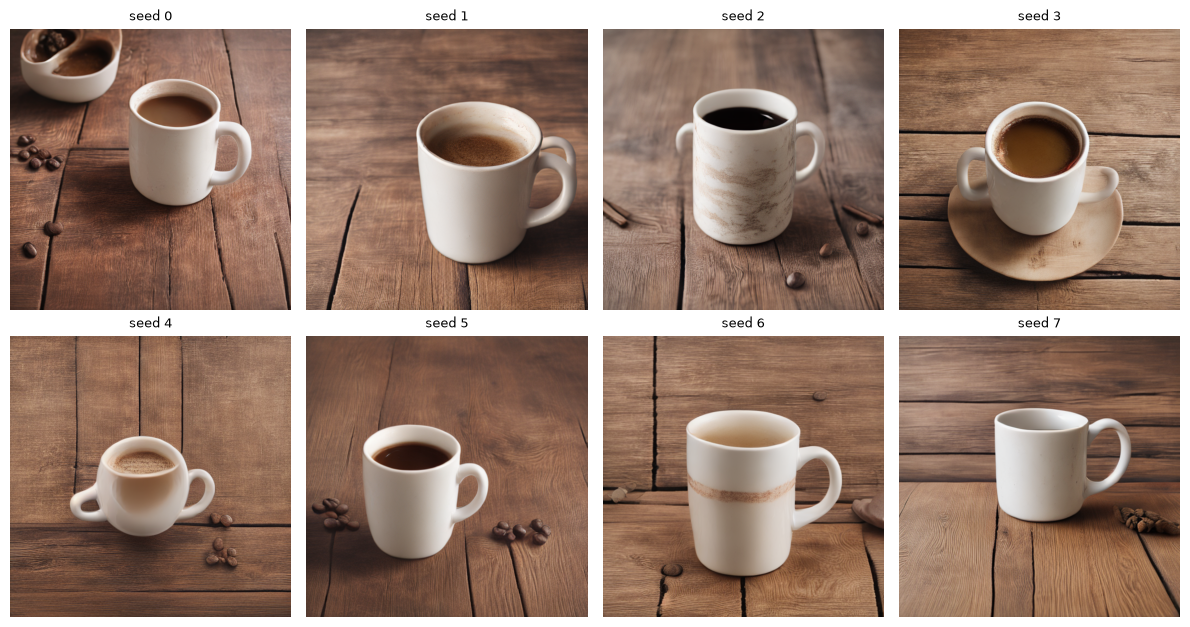

In [4]:
from diffusers import AutoPipelineForText2Image, AutoPipelineForImage2Image
from diffusers.utils import logging as diffusers_logging
diffusers_logging.set_verbosity_error()  # hide loading messages
diffusers_logging.disable_progress_bar()

turbo = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo", torch_dtype=dtype, variant="fp16"
).to(device)
turbo.set_progress_bar_config(disable=True)

def text_to_image(prompt, seed, steps=1):
    generator = torch.Generator("cpu").manual_seed(seed)
    # SD-Turbo was trained to work without classifier-free guidance, so guidance_scale stays at 0
    return turbo(prompt, num_inference_steps=steps, guidance_scale=0.0, generator=generator).images[0]

prompt = "a ceramic coffee mug on a wooden table, product photo"
seeds = list(range(8))
show_grid([text_to_image(prompt, s) for s in seeds], [f"seed {s}" for s in seeds])

Eight seeds give eight different mugs, which is the cheapest way to show people several options to pick from (Lecture 14). The seed also makes a result repeatable, so if you write it down you can get the same image again.

### More steps

SD-Turbo can also take a few more steps. This compares one, two and four steps for the same seed.

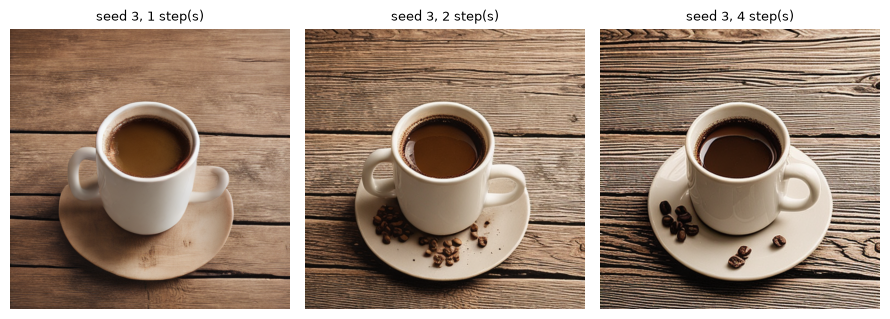

In [5]:
steps_list = [1, 2, 4]
show_grid([text_to_image(prompt, seed=3, steps=n) for n in steps_list],
          [f"seed 3, {n} step(s)" for n in steps_list], columns=3)

## 3. Change one word, keep the seed

With the same seed the model starts from the same noise, so a small change to the prompt often keeps much of the layout and changes the part you named. This is one way to make a small change, one of Shneiderman's three ideas of direct manipulation (Lecture 13), but it does not always work. For example, in the run below "blue" also moved the mug and dropped the saucer.

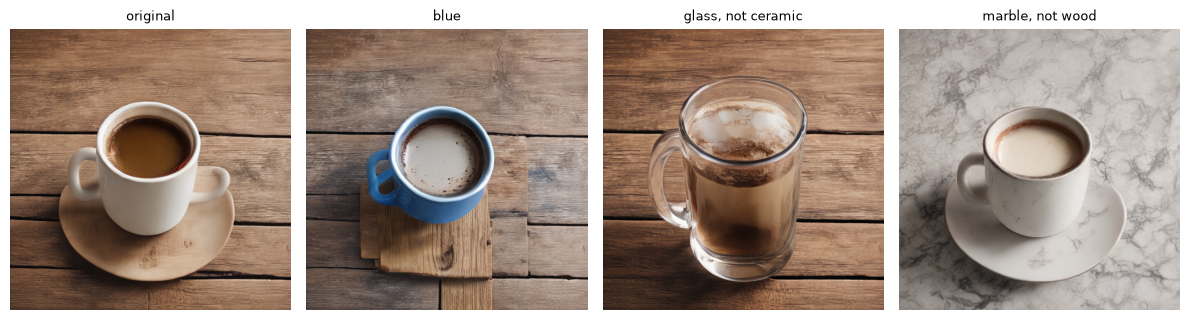

In [6]:
variants = [
    "a ceramic coffee mug on a wooden table, product photo",
    "a blue ceramic coffee mug on a wooden table, product photo",
    "a glass coffee mug on a wooden table, product photo",
    "a ceramic coffee mug on a marble table, product photo",
]
show_grid([text_to_image(p, seed=3) for p in variants],
          ["original", "blue", "glass, not ceramic", "marble, not wood"])

## 4. Image to image

Image to image adds some noise to an existing image and then removes it again, guided by the prompt. The strength sets how much noise is added, so near 0 the image barely changes and at 1 the starting image is gone. Tools that remix or vary a picture use this setting.

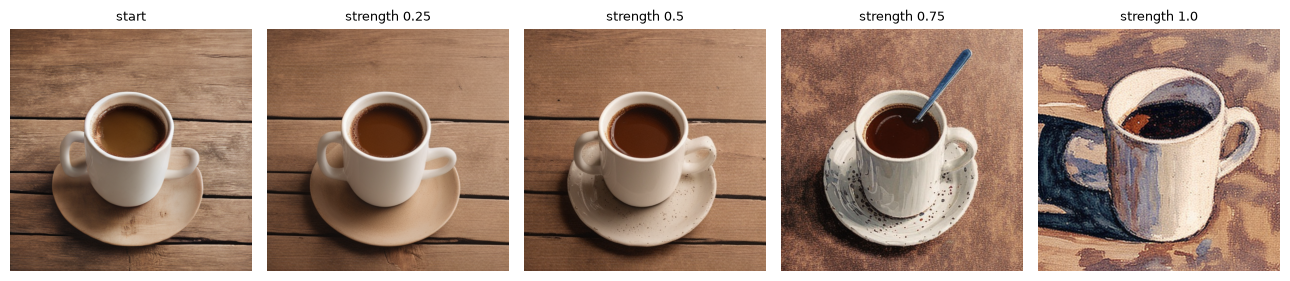

In [7]:
image_to_image = AutoPipelineForImage2Image.from_pipe(turbo)  # reuses the loaded model, no new download
image_to_image.set_progress_bar_config(disable=True)

start = text_to_image(prompt, seed=3)
new_prompt = "a watercolor painting of a coffee mug on a table"

def vary(image, prompt, strength, seed=0, steps=4):
    generator = torch.Generator("cpu").manual_seed(seed)
    # The model runs steps x strength denoising steps, so this needs to be at least 1.
    return image_to_image(prompt, image=image, strength=strength, num_inference_steps=steps,
                          guidance_scale=0.0, generator=generator).images[0]

strengths = [0.25, 0.5, 0.75, 1.0]
show_grid([start] + [vary(start, new_prompt, s) for s in strengths],
          ["start"] + [f"strength {s}" for s in strengths], columns=5, size=2.6)

## 5. Sketch to image with ControlNet

With a text prompt alone it is hard to say where things go (for example, where the handle is), but a sketch can show it. ControlNet adds a second network that reads an extra input such as a sketch and uses it at each step (Lecture 13). This frees SD-Turbo's memory and loads Stable Diffusion 1.5 with the scribble ControlNet. If its safety checker flags an image, the image comes out black.

In [8]:
del turbo, image_to_image
free_memory()

from diffusers import ControlNetModel, StableDiffusionControlNetPipeline, UniPCMultistepScheduler

controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/control_v11p_sd15_scribble", torch_dtype=dtype, variant="fp16"
)
sketch_pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", controlnet=controlnet, torch_dtype=dtype, variant="fp16"
).to(device)
sketch_pipe.scheduler = UniPCMultistepScheduler.from_config(sketch_pipe.scheduler.config)
sketch_pipe.set_progress_bar_config(disable=True)

STEPS = 20 if device != "cpu" else 12  # fewer steps on a CPU, so it does not take too long

### Draw a sketch

In Colab, the next cell shows a drawing area where you can draw with the mouse or a finger, then click Use this sketch. Outside Colab it draws a simple mug for you, which is the sketch in the outputs below. You can also upload a photo of a sketch on paper (folder icon on the left) and put its file name in `SKETCH_FILE`.

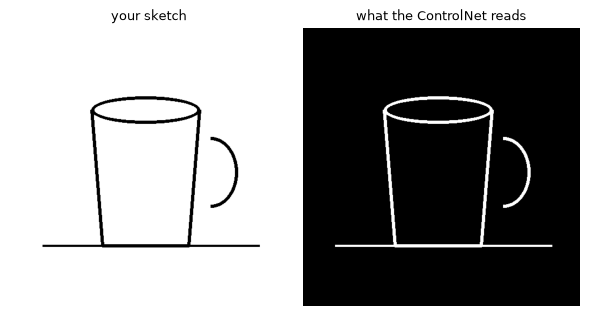

In [9]:
import base64, io

SKETCH_FILE = None  # for example "my_sketch.png"

CANVAS = """
<canvas id="sketch" width="512" height="512" style="border:1px solid #999; touch-action:none; cursor:crosshair"></canvas><br>
<button id="clear">Clear</button> <button id="done">Use this sketch</button>
<script>
const c = document.getElementById("sketch"), ctx = c.getContext("2d");
ctx.fillStyle = "white"; ctx.fillRect(0, 0, 512, 512);
ctx.lineWidth = 5; ctx.lineCap = "round"; ctx.strokeStyle = "black";
let down = false;
c.onpointerdown = e => { down = true; ctx.beginPath(); ctx.moveTo(e.offsetX, e.offsetY); };
c.onpointermove = e => { if (down) { ctx.lineTo(e.offsetX, e.offsetY); ctx.stroke(); } };
c.onpointerup = c.onpointerleave = () => { down = false; };
document.getElementById("clear").onclick = () => { ctx.fillStyle = "white"; ctx.fillRect(0, 0, 512, 512); };
var sketchData = new Promise(resolve => {
  document.getElementById("done").onclick = () => resolve(c.toDataURL("image/png"));
});
</script>
"""

def draw_in_colab():
    from google.colab.output import eval_js  # only exists on Colab
    from IPython.display import HTML, display
    display(HTML(CANVAS))
    data_url = eval_js("sketchData")  # waits until you click "Use this sketch"
    return Image.open(io.BytesIO(base64.b64decode(data_url.split(",")[1]))).convert("RGB")

def example_mug():
    img = Image.new("RGB", (512, 512), "white")
    d = ImageDraw.Draw(img)
    d.line([(150, 150), (170, 400), (330, 400), (350, 150)], fill="black", width=6)  # cup body
    d.ellipse([(150, 125), (350, 175)], outline="black", width=6)                   # rim
    d.arc([(320, 200), (420, 330)], start=-90, end=90, fill="black", width=6)        # handle
    d.line([(60, 400), (460, 400)], fill="black", width=4)                          # table edge
    return img

if SKETCH_FILE:
    sketch = Image.open(SKETCH_FILE).convert("RGB").resize((512, 512))
else:
    try:
        sketch = draw_in_colab()
    except Exception:
        sketch = example_mug()

# The scribble ControlNet was trained on white lines on a black background, so we flip the colors.
control_image = ImageOps.invert(sketch)
show_grid([sketch, control_image], ["your sketch", "what the ControlNet reads"], columns=2)

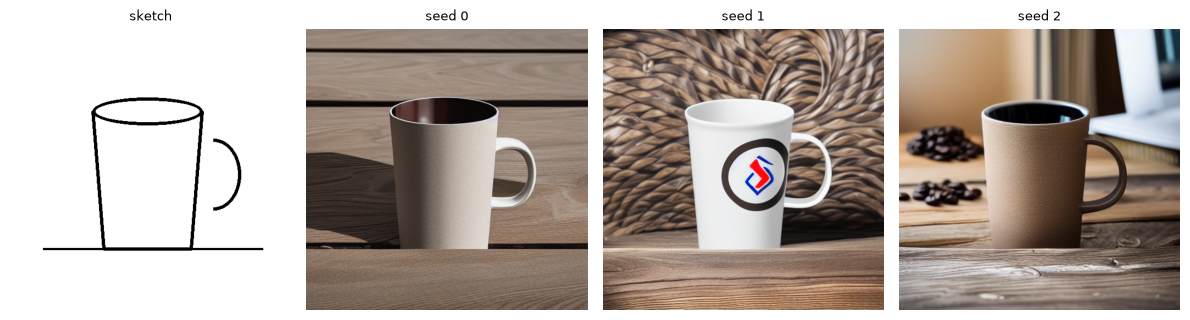

In [10]:
def sketch_to_image(prompt, control_image, seed=0, follow=1.0, steps=STEPS):
    generator = torch.Generator("cpu").manual_seed(seed)
    return sketch_pipe(
        prompt, image=control_image, num_inference_steps=steps, generator=generator,
        controlnet_conditioning_scale=follow,  # how much weight the sketch gets at each step
        negative_prompt="blurry, low quality",
    ).images[0]

sketch_prompt = "a ceramic coffee mug on a wooden table, product photo"
seeds = [0, 1, 2]
show_grid([sketch] + [sketch_to_image(sketch_prompt, control_image, seed=s) for s in seeds],
          ["sketch"] + [f"seed {s}" for s in seeds])

The seed still changes the colors, the light and the details, but the shape now comes from the sketch.

### How closely should it follow the sketch?

`controlnet_conditioning_scale` sets how much weight the sketch gets at each step, and at 0 the sketch is ignored. Higher values follow the lines more closely. This helps when your sketch is careful, but can hurt when it is rough.

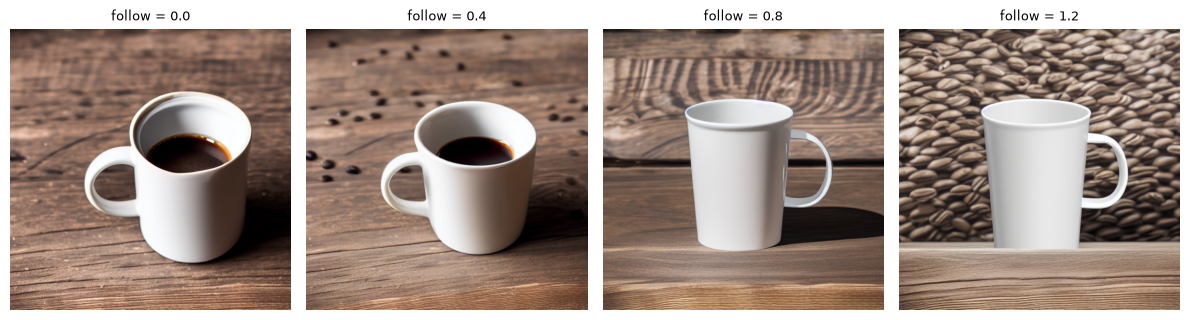

In [11]:
scales = [0.0, 0.4, 0.8, 1.2]
show_grid([sketch_to_image(sketch_prompt, control_image, seed=1, follow=f) for f in scales],
          [f"follow = {f}" for f in scales])

### Same sketch, different words

This keeps the sketch and the seed and changes the prompt, so you can see what the same shape turns into.

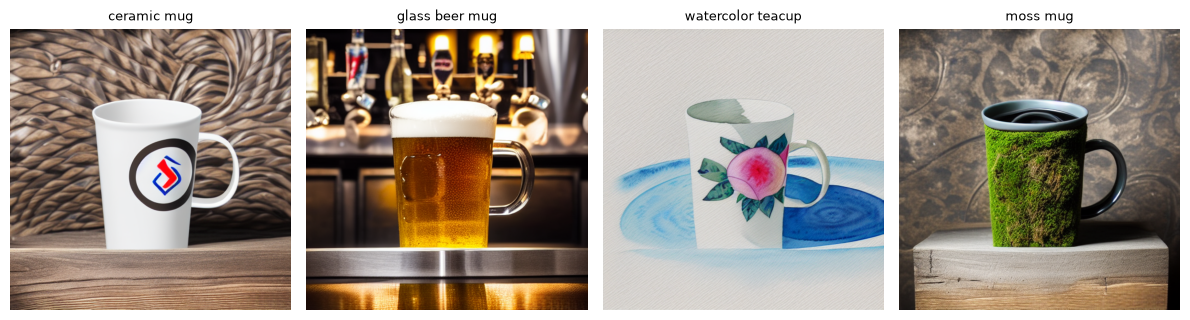

In [12]:
prompts = [
    "a ceramic coffee mug on a wooden table, product photo",
    "a glass beer mug on a bar counter, photo",
    "a watercolor painting of a teacup",
    "a mug made of moss, studio photo",
]
show_grid([sketch_to_image(p, control_image, seed=1) for p in prompts],
          ["ceramic mug", "glass beer mug", "watercolor teacup", "moss mug"])

## Exercises

These help with Milestone 3 (Make it steerable), where your team adds a way to steer the AI other than typing a prompt and tests it with 4 people.

**Exercise 1.** Pick a picture someone in your group might need (for example, a worksheet illustration for a music teacher or a poster for a club event), make 8 seeds and choose one. Then try to get one specific change, like moving something or changing one color, with each control here: a prompt edit with the same seed, image to image, and a sketch. Which control got you there, and which did not? You can save the images as a grid for your Milestone 3 report.

In [13]:
# Exercise 1: your code here

**Exercise 2.** Shneiderman's three ideas (Lecture 13) ask whether people can see what they are changing, act on it directly, and make a small change and undo it. Build a small history for one control that keeps every prompt, seed and setting a person tried with its image, shows them as a row of thumbnails, and lets the person go back to any earlier one.

In [14]:
# Exercise 2: your code here

**Exercise 3.** Choose the control that fits your group best and how a person would use it (for example, a slider for the strength or a drawing area for the sketch). Write down one thing a person could make the model do with it, and one thing they could not.

In [15]:
# Exercise 3: your code here

**Exercise 4.** To plan the test, make a target image with a seed you keep secret, and ask four classmates to get as close to it as they can with your control in five minutes. Save every image they make and put the results side by side (Lecture 14). How different are they, and which attempts got close?

In [16]:
# Exercise 4: your code here